# Where can we find more merchants like our best ones?

Notebook 02 described what an attractive Snap merchant looks like. This notebook asks the next question: **where can the other four datasets help us find more of them?**

**Flow:** 02 what makes an attractive merchant → **03 where to find more** → 04 who Sales should contact first → 05 how we measure it

| Section | Question |
|---|---|
| 1. Linking records | There is no shared ID. How do we tell the same business appears in several datasets, and how well does that work? |
| 2. Overlap | How much of each dataset is already known to Snap or to Sales? |
| 3. Each dataset | What is each dataset good for, and how would Sales use it? |
| 4. Comparison | Which datasets matter most? |

All counts use de-duplicated records (`dupe_record_rank = 1`) from the dbt staging models. The ranking rules and other assumptions are in [Assumptions](../docs/assumptions.md).

## Setup

In [128]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Walk up from the notebook's folder until the warehouse is found, so this works from any kernel start folder.
here = Path.cwd().resolve()
repo_root = next(p for p in [here, *here.parents] if (p / "warehouse" / "snap-assessment.duckdb").exists())

# read_only=True so the notebook never blocks `dbt build` from writing to the file.
con = duckdb.connect(str(repo_root / "warehouse" / "snap-assessment.duckdb"), read_only=True)

def q(sql: str) -> pd.DataFrame:
    """Run a SQL query and return the results as a Pandas DataFrame."""
    return con.sql(sql).df()

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [106]:
# Settings you may want to change
RECENT_ACTIVITY = ["Txn within 13 months"]   # card activity buckets treated as "recently active"

FLAGS = ["in_snap_active", "in_snap_inactive", "in_card", "in_purchased", "in_salesforce", "in_website"]
SHORT = {"in_snap_active": "Snap", "in_snap_inactive": "Snap (inactive)", "in_card": "Card",
         "in_purchased": "Purchased", "in_salesforce": "Salesforce", "in_website": "Website"}

# Presence in these means "Snap or Sales already knows this business". Card and purchased are lists we bought, so they don't count.
KNOWN = ["in_snap_active", "in_snap_inactive", "in_salesforce", "in_website"]

## 1. Linking records across datasets

None of the five files share an ID, so I link them by business name and location. Two keys, both built from the cleaned staging fields:

- **loose key:** cleaned name + ZIP5
- **strict key:** cleaned name + cleaned street + ZIP5

State is left out on purpose. In several datasets the state field disagrees with the address and ZIP, so it would cause misses rather than prevent false matches.

**Limits to keep in mind**
- Exact matching only. A name spelled two ways, or `Street` versus `St`, is a miss, so every match rate here is a **floor**.
- The loose key can merge two different businesses with the same name in the same ZIP. The strict key avoids that but misses more.
- Records with no name or no valid ZIP5 cannot be linked at all.
- Some website and Salesforce street fields hold a full address, which hurts the strict key more than the loose one.

In [107]:
keys = q("""
with u as (
    select case when is_inactivated then 'snap_inactive' else 'snap_active' end as src,
           mid::varchar as source_id, 
           company_name_clean as name_c, 
           street_address_clean as street_c, 
           zip_code_5_digit as zip5
    from "snap-assessment".staging.stg_snap where dupe_record_rank = 1

    union all

    select 'card', merchant_outlet_number::varchar, company_name_clean, street_address_clean, zip_code_5_digit
    from "snap-assessment".staging.stg_card_list where dupe_record_rank = 1

    union all

    select 'purchased', speedeonid::varchar, company_name_clean, street_address_clean, zip_code_5_digit
    from "snap-assessment".staging.stg_purchased_list where dupe_record_rank = 1

    union all

    select 'salesforce', id::varchar, company_name_clean, street_address_clean, zip_code_5_digit
    from "snap-assessment".staging.stg_salesforce_list where dupe_record_rank = 1

    union all

    select 'website', lead_id::varchar, company_name_clean, street_address_clean, zip_code_5_digit
    from "snap-assessment".staging.stg_website_list where dupe_record_rank = 1
)
select src, source_id,
       nullif(name_c, '') || '|' || zip5 as loose_key,
       nullif(name_c, '') || '|' || nullif(street_c, '') || '|' || zip5 as strict_key
from u
""")
con.register("keys", keys)

keys.groupby("src").agg(records=("source_id", "size"),
                        no_key=("loose_key", lambda s: int(s.isna().sum())))

,records,no_key
src,,
card,1307,0
purchased,994,0
salesforce,1271,47
snap_active,654,0
snap_inactive,552,0
website,1011,102


`no_key` is the number of records that cannot be linked because the name or ZIP5 is missing or invalid.

**How well do the other datasets link to Snap?** Strict versus loose shows how much the street field costs us.

In [108]:
match_rates = q("""
with snap_k as (
    select distinct loose_key, strict_key from keys
    where src in ('snap_active', 'snap_inactive') and loose_key is not null
)
select 
    src as source,
    count(*) as records,
    round(100.0 * count(*) filter (where loose_key  in (select loose_key  from snap_k)) / count(*), 1) as pct_in_snap_loose,
    round(100.0 * count(*) filter (where strict_key in (select strict_key from snap_k)) / count(*), 1) as pct_in_snap_strict
from keys
where src not in ('snap_active', 'snap_inactive')
group by src order by records desc
""")
match_rates

,source,records,pct_in_snap_loose,pct_in_snap_strict
0,card,1307,11.4,7.7
1,salesforce,1271,23.8,9.8
2,website,1011,13.1,8.3
3,purchased,994,7.5,5.6


## 2. Overlap: what is already known?

One row per business (strict key) with a flag for each dataset it appears in.

In [109]:
entity = q("""

select 
    strict_key,
    bool_or(src = 'snap_active')   as in_snap_active,
    bool_or(src = 'snap_inactive') as in_snap_inactive,
    bool_or(src = 'card')          as in_card,
    bool_or(src = 'purchased')     as in_purchased,
    bool_or(src = 'salesforce')    as in_salesforce,
    bool_or(src = 'website')       as in_website
from keys 
where strict_key is not null
group by strict_key

""")
con.register("entity", entity)

combos = entity[FLAGS].value_counts().reset_index(name="n_businesses")
combos["sources"] = combos[FLAGS].apply(lambda r: " + ".join(SHORT[f] for f in FLAGS if r[f]), axis=1)
combos["pct"] = (100 * combos["n_businesses"] / combos["n_businesses"].sum()).round(1)
print(f"{len(entity):,} distinct businesses across all five datasets")
combos[["sources", "n_businesses", "pct"]].head(15)

4,373 distinct businesses across all five datasets


,sources,n_businesses,pct
0,Card,919,21.0
1,Purchased,686,15.7
2,Salesforce,546,12.5
3,Snap,495,11.3
4,Snap (inactive),453,10.4
5,Salesforce + Website,352,8.0
6,Website,313,7.2
7,Card + Purchased,139,3.2
8,Snap + Salesforce,50,1.1
9,Card + Salesforce,50,1.1


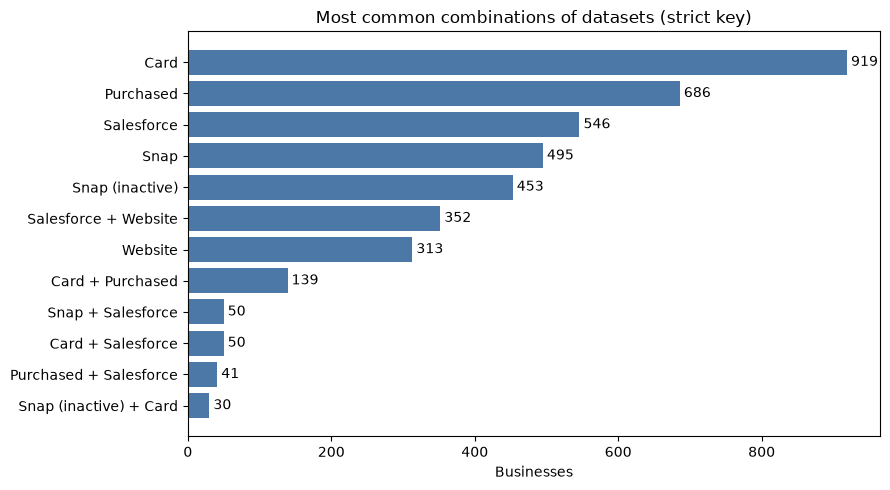

In [110]:
top = combos.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["sources"], top["n_businesses"], color="#4C78A8")
for y, v in enumerate(top["n_businesses"]):
    ax.text(v, y, f" {v:,}", va="center")
ax.set_xlabel("Businesses")
ax.set_title("Most common combinations of datasets (strict key)")
plt.tight_layout()
plt.show()

**For each dataset (row), what share of its linkable records also appear in each other dataset (column)?**

In [111]:
rec = keys.merge(entity, on="strict_key", how="left")          # one row per record, with the flags of its business
rec[FLAGS] = rec[FLAGS].fillna(False).astype(bool)
linkable = rec[rec["strict_key"].notna()]                        # records with no usable name/ZIP can't be placed in the overlap

SRC = ["snap_active", "snap_inactive", "card", "purchased", "salesforce", "website"]
overlap = pd.DataFrame({SHORT["in_" + o]: {s: round(100 * linkable.loc[linkable.src == s, "in_" + o].mean(), 1) for s in SRC} for o in SRC})
overlap.index = [SHORT["in_" + s] for s in SRC]
overlap

,Snap,Snap (inactive),Card,Purchased,Salesforce,Website
Snap,100.0,0.0,8.4,4.3,12.7,8.0
Snap (inactive),0.0,100.0,8.2,5.1,7.1,4.7
Card,4.3,3.4,100.0,15.5,9.2,6.7
Purchased,2.8,2.8,20.2,100.0,8.7,7.0
Salesforce,7.1,3.3,10.2,7.6,100.0,39.6
Website,6.2,3.1,10.5,9.8,53.1,100.0


The diagonal is always 100%. Read across a row. Using strict key, 8.4% of Snap (active) data is in the Card list dataset.

## 3. What each dataset is good for

Each section uses the same shape: **what it is for → evidence → how Sales would use it.** A small helper adds the overlap flags to each de-duplicated staging table.

In [112]:
FLAG_SELECT = ", ".join(f"coalesce(e.{f}, false) as {f}" for f in FLAGS)

def flagged(table: str, id_col: str, cols: list, own: str) -> pd.DataFrame:
    """De-duplicated records from a staging table, plus a flag for each dataset the same business appears in.
    already_known = the business is in Snap, Salesforce or the website list (ignoring the dataset it came from).
    net_new = we could link the record AND found it nowhere in those. Records with no usable name/ZIP are never called new."""
    select_cols = ", ".join(f"t.{c}" for c in cols)
    df = q(f"""
        select 
          t.{id_col}::varchar as source_id, 
          {select_cols}, 
          {FLAG_SELECT},
          (nullif(t.company_name_clean, '') || '|' || t.zip_code_5_digit) is not null as linkable
        from "snap-assessment".staging.{table} t
        left join entity e
          on nullif(t.company_name_clean, '') || '|' || nullif(t.street_address_clean, '') || '|' || t.zip_code_5_digit = e.strict_key
        where t.dupe_record_rank = 1
    """)
    df["already_known"] = df[[c for c in KNOWN if c != f"in_{own}"]].any(axis=1)
    df["net_new"] = df["linkable"] & ~df["already_known"]
    return df

### 3a. Card list: who is still transacting?

**What it is for:** finding real, active businesses. `last_activity_period` is the freshness signal (and a hint that a business may have closed), and `mcc_id` says what kind of business it is.

In [113]:
card = flagged("stg_card_list", "merchant_outlet_number", ["last_activity_period", "mcc_id_list"], own="card")
card["is_recent"] = card["last_activity_period"].isin(RECENT_ACTIVITY)

recency = (card.groupby("last_activity_period")
               .agg(outlets=("source_id", "size"),
                    pct_already_in_snap=("in_snap_active", lambda s: round(100 * s.mean(), 1)),
                    not_known_to_snap_or_sales=("net_new", "sum"))
               .sort_values("outlets", ascending=False))
recency["pct_of_outlets"] = (100 * recency["outlets"] / recency["outlets"].sum()).round(1)
recency

,outlets,pct_already_in_snap,not_known_to_snap_or_sales,pct_of_outlets
last_activity_period,,,,
Txn within 13 months,1040,5.2,829,79.6
Txn between 14-24 months ago,86,1.2,77,6.6
Reg inactive with txn between 3 and 13 months,57,1.8,51,4.4
Txn between 2-3 years ago,44,0.0,40,3.4
Txn before 3 years ago,39,0.0,39,3.0
No Txn,38,0.0,31,2.9
Reg inactive with txn in last 3 months,3,0.0,3,0.2


In [114]:
card_mcc = q("""
    select 
        merchant_outlet_number::varchar as source_id,
        string_agg(distinct mcc_description, '; ') as mcc_description,
        bool_or(regexp_matches(coalesce(mcc_description, ''), 'automotive|tire|furniture|appliance|jewel', 'i')) as proven_mcc
    from "snap-assessment".intermediate.int_card_mcc
    group by 1
""")
n_before = len(card)
card = card.merge(card_mcc, on="source_id", how="left")
assert len(card) == n_before, "merge duplicated outlets"
card["proven_mcc"] = card["proven_mcc"].fillna(False)

**The card-list funnel:** from every outlet down to the pool worth a Sales call.

,outlets,pct_of_start
Card outlets (de-duplicated),1307,100.0
...active recently,1040,79.6
...in a proven industry (by MCC),992,75.9
...and not already known to Snap or Sales,787,60.2


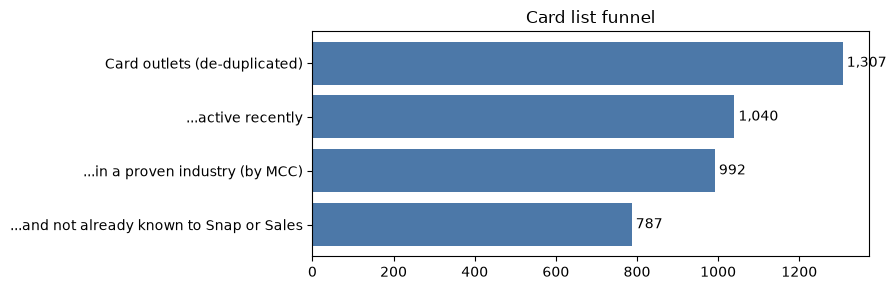

In [129]:
funnel = pd.Series({
    "Card outlets (de-duplicated)": len(card),
    "...active recently": int(card["is_recent"].sum()),
    "...in a proven industry (by MCC)": int((card["is_recent"] & card["proven_mcc"]).sum()),
    "...and not already known to Snap or Sales": int((card["is_recent"] & card["proven_mcc"] & card["net_new"]).sum()),
}, name="outlets").to_frame()
funnel["pct_of_start"] = (100 * funnel["outlets"] / funnel["outlets"].iloc[0]).round(1)
display(funnel)

fig, ax = plt.subplots(figsize=(9, 3))
ax.barh(funnel.index[::-1], funnel["outlets"][::-1], color="#4C78A8")
for y, v in enumerate(funnel["outlets"][::-1]):
    ax.text(v, y, f" {v:,}", va="center")
ax.set_title("Card list funnel")
plt.tight_layout()
plt.show()

**How Sales would use it:** the last funnel step is a ready-made call list of active nobody has contacted. More work could be down to use the `mcc_id` field to get industry type.

### 3b. Purchased list: the wider universe, with size signals

**What it is for:** a broad list with cleaner addresses plus `location_employee_count`, `labels_square_footage` and an SIC industry. The test below asks whether the purchased records that match active Snap merchants look different in size from the rest. If they do, size is a usable filter for finding lookalikes. There are no outcome labels, so this is an association, not proof.

In [116]:
pur = flagged("stg_purchased_list", "speedeonid",
              ["primary_sic_code_id", "labels_primary_sic_code_id", "location_employee_count", "labels_square_footage"], own="purchased")

size_cmp = (pur.groupby("in_snap_active")
               .agg(records=("source_id", "size"),
                    employees_missing_pct=("location_employee_count", lambda s: round(100 * s.isna().mean(), 1)),
                    median_employees=("location_employee_count", "median")
                    )
          )
size_cmp.index = size_cmp.index.map({True: "matches an active Snap merchant", False: "does not match"})
display(size_cmp)

sqft = (pd.crosstab(pur["labels_square_footage"].fillna("(missing)"), pur["in_snap_active"])
          .reindex(columns=[False, True], fill_value=0))
sqft.columns = ["not matched", "matched"]

sqft["not matched %"] = (100 * sqft["not matched"] / sqft["not matched"].sum()).round(1)
sqft["matched %"]     = (100 * sqft["matched"] / sqft["matched"].sum()).round(1)
# % of each size bucket that is a Snap match: the more intuitive view
sqft["% of bucket that is Snap"] = (100 * sqft["matched"] / (sqft["matched"] + sqft["not matched"])).round(1)

# sort by the first number in the label, with "(missing)" last
order = (sqft.index.to_series().str.replace(",", "").str.extract(r"(\d+)")[0].astype(float).fillna(1e12))
sqft = sqft.loc[order.sort_values().index]
sqft

,records,employees_missing_pct,median_employees
in_snap_active,,,
does not match,966,30.4,4.0
matches an active Snap merchant,28,21.4,5.0


,not matched,matched,not matched %,matched %,% of bucket that is Snap
labels_square_footage,,,,,
"1 - 1,499",336,10,34.8,35.7,2.9
"1,500 - 2,499",241,10,24.9,35.7,4.0
"2,500 - 4,999",166,3,17.2,10.7,1.8
"5,000 - 9,999",41,2,4.2,7.1,4.7
"10,000 - 19,999",35,1,3.6,3.6,2.8
"20,000 - 39,999",14,1,1.4,3.6,6.7
"40,000 - 99,999",10,0,1.0,0.0,0.0
"100,000+",12,0,1.2,0.0,0.0
(missing),111,1,11.5,3.6,0.9


**Which industries (SIC) are in the list, and how many are not known to Snap or Sales yet?**

In [117]:
sic = (pur.groupby("labels_primary_sic_code_id")
          .agg(records=("source_id", "size"),
               in_snap=("in_snap_active", "sum"),
               not_known=("net_new", "sum"))
          .sort_values("records", ascending=False).head(15))
sic

,records,in_snap,not_known
labels_primary_sic_code_id,,,
Automobile Repairing & Service,334,14,269
Tire-Dealers-Retail,145,5,118
Furniture-Dealers-Retail,105,2,90
Automobile Body-Repairing & Painting,52,1,43
Jewelers-Retail,44,3,37
Automobile Parts & Supplies-Retail-New,32,0,24
Transmissions-Automobile,31,0,27
Ignition Interlock Devices-Install & Svc,29,0,29
Appliances-Household-Major-Dealers,26,0,19


In [118]:
matched = pur[pur["in_snap_active"]]
SIZE_FLOOR = matched["location_employee_count"].median() if len(matched) else np.nan   # median size of Snap-matched locations

new_pool = pur[pur["net_new"]]
print(f"Purchased locations not known to Snap or Sales (linkable records only): {len(new_pool):,}")
if not np.isnan(SIZE_FLOOR):
    sized = new_pool[new_pool["location_employee_count"] >= SIZE_FLOOR]
    print(f"...with at least {SIZE_FLOOR:.0f} employees (median of Snap-matched locations): {len(sized):,}")

Purchased locations not known to Snap or Sales (linkable records only): 825
...with at least 5 employees (median of Snap-matched locations): 260


**How Sales would use it:** as the prospecting universe for lookalikes, ranked by size and industry. The low match results does not help create strong cases though. 

### 3c. Salesforce: what is already in the pipeline?

**What it is for:** the work Sales has already done: status, estimated opportunity (TSO), lead age, and why leads were disqualified.

In [119]:
sf = flagged("stg_salesforce_list", "id",
             ["status", "industry_vertical__c", "total_snap_opportunity_tso__c", "age_of_lead__c",
              "disqualified_reason__c", "competitor_1_pll__c"], own="salesforce")
sf["bucket"] = sf["status"].where(sf["status"].isin(["Disqualified", "Converted"]), "Open")

(sf.groupby("bucket")
   .agg(leads=("source_id", "size"),
        total_tso=("total_snap_opportunity_tso__c", "sum"),
        avg_age_days=("age_of_lead__c", "mean"),
        pct_in_snap_active=("in_snap_active", lambda s: round(100 * s.mean(), 1)))
   .round(0).sort_values("leads", ascending=False))

,leads,total_tso,avg_age_days,pct_in_snap_active
bucket,,,,
Disqualified,616,1522620.0,702.0,3.0
Converted,466,11012766.0,794.0,14.0
Open,189,3072611.0,669.0,1.0


In [120]:
chk = sf[sf["disqualified_reason__c"] == "Merchant already Exists in Snap App"]
print(f"{len(chk)} leads that should be in Snap")
print(f"found in Snap (active): {chk['in_snap_active'].mean():.0%}")
print(f"found in Snap (active or inactive): {(chk['in_snap_active'] | chk['in_snap_inactive']).mean():.0%}")

87 leads that should be in Snap
found in Snap (active): 3%
found in Snap (active or inactive): 7%


**Open question from my notes: does `Converted` mean the business is already in Snap?** 

Compare converted leads against the Snap list.

In [121]:
conv = sf[sf["bucket"] == "Converted"]
conv_check = pd.Series({
    "In Snap (active)": int(conv["in_snap_active"].sum()),
    "In Snap (inactive only)": int((conv["in_snap_inactive"] & ~conv["in_snap_active"]).sum()),
    "Not found in Snap": int((~conv["in_snap_active"] & ~conv["in_snap_inactive"]).sum()),
}, name="converted leads").to_frame()
conv_check["pct"] = (100 * conv_check["converted leads"] / len(conv)).round(1)
conv_check

,converted leads,pct
In Snap (active),66,14.2
In Snap (inactive only),24,5.2
Not found in Snap,376,80.7


So many converted leads are not found in snap merchant list, either too strict on match or maybe assuming what `converted` meant.

In [122]:
open_leads = sf[sf["bucket"] == "Open"]
display(open_leads.groupby("status")
                  .agg(leads=("source_id", "size"),
                       total_tso=("total_snap_opportunity_tso__c", "sum"),
                       avg_age_days=("age_of_lead__c", "mean"))
                  .round(0).sort_values("leads", ascending=False))

open_leads.groupby("industry_vertical__c").agg(leads=("source_id", "size"),
                                              total_tso=("total_snap_opportunity_tso__c", "sum")).round(0).sort_values("total_tso", ascending=False).head(10)

,leads,total_tso,avg_age_days
status,,,
Nurturing,173,2608923.0,701.0
Working,5,0.0,23.0
Merchant Invitation Sent,4,463688.0,237.0
MQL,3,0.0,830.0
Awaiting Approval,1,0.0,606.0
BDR Working,1,0.0,915.0
New,1,0.0,0.0
Submit to Join,1,0.0,72.0


,leads,total_tso
industry_vertical__c,,
AUTO_SERVICE,68,924256.0
JEWELRY,9,824928.0
TIRES_RIMS,40,435012.0
OTHER,3,374987.0
FURNITURE,28,161024.0
CAR_AUDIO,3,52404.0
APPLIANCES,10,0.0
COLLISION_REPAIR,5,0.0
ELECTRONICS,2,0.0


**Why were leads disqualified, and to whom were they lost?** 

Disqualified leads may be worth re-engaging, depending on the reason.

In [123]:
(sf[sf["bucket"] == "Disqualified"]
   .groupby(["disqualified_reason__c", "competitor_1_pll__c"], dropna=False)
   .agg(leads=("source_id", "size"), total_tso=("total_snap_opportunity_tso__c", "sum"))
   .round(0).sort_values("leads", ascending=False).head(15))

,,leads,total_tso
disqualified_reason__c,competitor_1_pll__c,,
Denied by Decisioning,NaN,132,239985.0
Duplicate Lead,NaN,93,0.0
Merchant already Exists in Snap App,NaN,78,0.0
Not an approved vertical,NaN,62,0.0
Not a Good Fit,NaN,43,0.0
QuikTrak,NaN,42,0.0
Store Closed,NaN,31,0.0
NaN,NaN,27,0.0
Merchant was previously shut down,NaN,16,0.0


**How Sales would use it:** work the open leads (oldest and highest TSO first), exclude converted leads, and split the disqualified ones into "lost to a competitor" (re-engage with a pitch against that competitor) versus "not a fit" (leave alone).

### 3d. Website list: who is raising their hand?

**What it is for:** inbound intent. These businesses asked to talk to us, so the question is whether they are new or already in our systems.

In [124]:
web = flagged("stg_website_list", "lead_id", ["form_name", "industry_name", "industry_subcategory"], own="website")
web["segment"] = np.select(
    [~web["linkable"], web["in_snap_active"], web["in_snap_inactive"], web["in_salesforce"]],
    ["Can't link (missing name or ZIP)", "Already an active Snap merchant", "Former (inactive) Snap merchant", "Already in Salesforce"],
    default="New to us",
)

seg = web["segment"].value_counts().to_frame("leads")
seg["pct"] = (100 * seg["leads"] / seg["leads"].sum()).round(1)
display(seg)

pd.crosstab(web["form_name"], web["segment"])

,leads,pct
segment,,
Already in Salesforce,434,42.9
New to us,391,38.7
Can't link (missing name or ZIP),102,10.1
Already an active Snap merchant,56,5.5
Former (inactive) Snap merchant,28,2.8


segment,Already an active Snap merchant,Already in Salesforce,Can't link (missing name or ZIP),Former (inactive) Snap merchant,New to us
form_name,,,,,
LONG_FORM,56,434,0,28,391
SHORT_FORM,0,0,102,0,0


The short form missing ZIP looks like something is wrong with the form.

In [125]:
(web[web["segment"] == "New to us"]
    .groupby(["industry_name", "industry_subcategory"], dropna=False)
    .size().sort_values(ascending=False).head(10).to_frame("new_leads"))

new_leads
industry_name    industry_subcategory           
AUTOMOTIVE       AUTO_SERVICE                166
                 TIRES_RIMS                   44
NaN              NaN                          29
AUTOMOTIVE       COLLISION_REPAIR             24
RETAIL           OTHER                        17
                 JEWELRY                      16
AUTOMOTIVE       OTHER                        14
RETAIL           FURNITURE                    14
ELECTRONICS      OTHER                        13
HOME IMPROVEMENT FURNITURE                     9

**How Sales would use it:** `New to us` leads are the speed-to-lead tier. They should be contacted first, ahead of any cold list. Leads that match an active or former Snap merchant may be a new location of a business we already know, which could convert more easily, so they should go to the account owner. 

## 4. Which datasets matter most?

In [126]:
QUALITY = {"card": "High", "purchased": "High", "salesforce": "Medium", "website": "Low"}   # filled in from the scorecard at the end of notebook 01
SIGNAL = {"card": "Recent card activity", "purchased": "Size (employees, sq ft) + SIC industry",
          "salesforce": "Opportunity (TSO), status, lead age, competitor", "website": "Inbound intent"}
USE = {"card": "Cold list of active businesses", "purchased": "Lookalike universe, ranked by size",
       "salesforce": "Work open leads; re-engage lost ones", "website": "Speed-to-lead"}

rows = []
for src, label in [("card", "Card list"), ("purchased", "Purchased list"), ("salesforce", "Salesforce list"), ("website", "Website list")]:
    d = rec[rec["src"] == src]
    ok = d["loose_key"].notna()
    known = d[[c for c in KNOWN if c != f"in_{src}"]].any(axis=1)
    rows.append({
        "dataset": label,
        "records": len(d),
        "unlinkable": int((~ok).sum()),
        "pct_in_snap_active": round(100 * d.loc[ok, "in_snap_active"].mean(), 1),
        "net_new_records": int((ok & ~known).sum()),
        "pct_net_new": round(100 * (ok & ~known).mean(), 1),
        "quality_rating": QUALITY[src],
        "strongest_signal": SIGNAL[src],
        "how_sales_uses_it": USE[src],
    })
pd.DataFrame(rows)

,dataset,records,unlinkable,pct_in_snap_active,net_new_records,pct_net_new,quality_rating,strongest_signal,how_sales_uses_it
0,Card list,1307,0,4.3,1070,81.9,High,Recent card activity,Cold list of active businesses
1,Purchased list,994,0,2.8,825,83.0,High,"Size (employees, sq ft) + SIC industry","Lookalike universe, ranked by size"
2,Salesforce list,1271,47,6.9,675,53.1,Medium,"Opportunity (TSO), status, lead age, competitor",Work open leads; re-engage lost ones
3,Website list,1011,102,6.2,391,38.7,Low,Inbound intent,Speed-to-lead


*Net new* means the record could be linked and the business does not appear in Snap, Salesforce or the website list (excluding the dataset itself). Records with no usable name or ZIP are never counted as new. The exact-match caveat from section 1 applies, so net-new counts are an **upper bound**.

## Takeaways

**Bottom line:** The five datasets are mostly *different* businesses, not five views of the same list. The biggest untapped value is (1) a stale but large Salesforce nurture backlog and (2) recently active card businesses nobody has contacted, with inbound website leads as the speed-to-lead tier. Linking records is the main limit on all of this.

### 1. How well do the datasets link?
- There is no shared ID, so I match on cleaned name + street + ZIP5 (strict) or name + ZIP5 (loose). Matching is exact, so every match rate is a floor.
- Strict is much more conservative: matches to Snap are 7.8% vs 11.5% (card), 9.8% vs 23.8% (Salesforce), 8.3% vs 13.1% (website) and 5.6% vs 7.5% (purchased). The street field costs the most on Salesforce.
- 47 Salesforce and 102 website records can't be linked at all. All 102 website records are `SHORT_FORM` submissions with no address details.
- 80.7% of `Converted` Salesforce leads are not found in Snap, so either `Converted` doesn't mean "now a Snap merchant" or the matching misses real overlap.

### 2. Which datasets bring new businesses?
| Dataset | Records | Not in Snap, Salesforce or website list |
|---|---|---|
| Card list | 1,314 | 1,073 (82%) |
| Purchased list | 994 | 825 (83%) |
| Salesforce | 1,271 | 675 (53%) |
| Website | 1,011 | 391 (39%) |
- The card and purchased lists are almost entirely new to Snap and Sales. The website list mostly repeats Salesforce (43% are already there).
- These counts are upper bounds because exact matching misses near-duplicates.

### 3. Where is the best untapped pool?
- **Salesforce backlog:** 189 open leads, 173 of them `Nurturing`, holding about $2.6M of the $3.1M open TSO at an average age of about 700 days. Jewelry is the standout: 9 open leads carry $825K (about $92K each), against about $14K per lead in Auto Service.
- **Card list:** 1,044 of 1,314 outlets (79.5%) transacted within 13 months, and 831 of those aren't known to Snap or Sales. This pool isn't filtered by industry yet.
- **Website:** 391 leads are new to us (166 Auto Service, 44 Tires/Rims), the speed-to-lead tier.
- **Purchased list:** 825 locations not known to Snap or Sales, but size is not a proven filter (see below).

### 4. What I would confirm before deploying
- **Match quality:** test recall on the 78 leads disqualified as "Merchant already Exists in Snap App". They should all match. If many don't, the match key is missing real overlap and the net-new counts are inflated.
- **What `Converted` means** with the business, since 81% of converted leads aren't in Snap.
- **Size as a lookalike filter:** only 28 purchased records match active Snap merchants (median 5 employees vs 4), and the share of each size bucket that is Snap is flat (about 2 to 4%). That is too small to conclude anything.
- **Industry for the card list:** MCC codes aren't mapped to Snap industries yet.
- **The short-form ZIP gap:** whether that is a form design problem or missing data capture.

These feed notebook 04, where the same linked table becomes a tiered list for Sales.


In [127]:
con.close()